# =============================================================================
# Author: G.A.N.M.Perera
# Student ID: 20240694
# Peer Reviewer: [Enter Peer Name Here]
# Review Date: 15/04/2026
# Module: 5DATA002W.2 — Machine Learning & Data Mining
# Task: Notebook 2  
# =============================================================================

In [3]:
# Import core libraries for data manipulation and modeling
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Load the cleaned dataset
df = pd.read_csv('/content/drive/MyDrive/cleaned_loan_data.csv')

# Encode categorical variables into numerical format for model compatibility
le = LabelEncoder()
categorical_cols = df.select_dtypes(include=['object']).columns

for col in categorical_cols:
    df[col] = le.fit_transform(df[col].astype(str))

# Define the target variable and feature set
target_col = 'loan_approval_status'
y = df[target_col]

# Remove the target variable and non-predictive identifiers from the feature set
X = df.drop(columns=[target_col, 'id'], errors='ignore')

# Split the data into training (70%) and testing (30%) sets
# Stratification ensures consistent class distribution across sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)

# Standardize features to a common scale
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Verify dataset dimensions and features
print("Features used:", X.columns.tolist())
print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/cleaned_loan_data.csv'

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from sklearn.impute import SimpleImputer

# Address missing values using the mean strategy
imputer = SimpleImputer(strategy='mean')
X_train_final = imputer.fit_transform(X_train_scaled)

# Initialize and train the Logistic Regression model
lr_model = LogisticRegression(random_state=42)
lr_model.fit(X_train_final, y_train)

# Initialize and train the Gaussian Naive Bayes model
nb_model = GaussianNB()
nb_model.fit(X_train_final, y_train)

# Initialize and train the K-Nearest Neighbors model
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_final, y_train)

print("Logistic Regression, Naive Bayes, and KNN models trained successfully.")

Logistic Regression, Naive Bayes, and KNN models trained successfully.


--- Naive Bayes Performance ---
Confusion Matrix:
[[15089     0]
 [    5  2500]]

Detailed Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     15089
           1       1.00      1.00      1.00      2505

    accuracy                           1.00     17594
   macro avg       1.00      1.00      1.00     17594
weighted avg       1.00      1.00      1.00     17594

AUC-ROC Score: 1.0000

--- Logistic Regression Performance ---
Confusion Matrix:
[[15043    46]
 [    2  2503]]

Detailed Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     15089
           1       0.98      1.00      0.99      2505

    accuracy                           1.00     17594
   macro avg       0.99      1.00      0.99     17594
weighted avg       1.00      1.00      1.00     17594

AUC-ROC Score: 0.9999

--- KNN Performance ---
Confusion Matrix:
[[14987   102]
 [  299

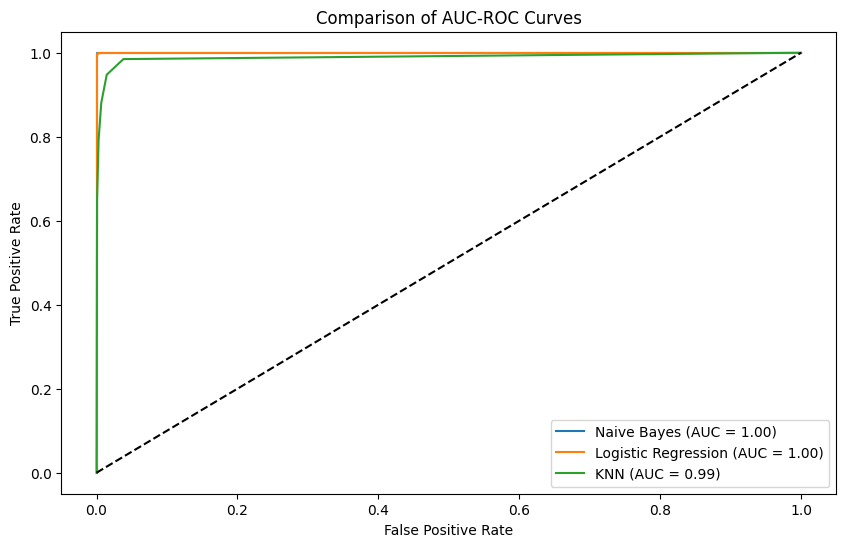

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, roc_curve
import matplotlib.pyplot as plt

# Impute missing values in the test set using training data parameters
X_test_final = imputer.transform(X_test_scaled)

def evaluate_model(model, X_test_data, y_test_data, name):
    """Generates performance metrics and ROC plots for a given model."""
    y_pred = model.predict(X_test_data)
    y_prob = model.predict_proba(X_test_data)[:, 1]

    print(f"--- {name} Performance ---")
    print("Confusion Matrix:")
    print(confusion_matrix(y_test_data, y_pred))

    print("\nDetailed Classification Report:")
    print(classification_report(y_test_data, y_pred))

    auc = roc_auc_score(y_test_data, y_prob)
    print(f"AUC-ROC Score: {auc:.4f}\n")

    # Plot the ROC curve
    fpr, tpr, _ = roc_curve(y_test_data, y_prob)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.2f})')

# Execute evaluation for all models
plt.figure(figsize=(10, 6))
evaluate_model(nb_model, X_test_final, y_test, "Naive Bayes")
evaluate_model(lr_model, X_test_final, y_test, "Logistic Regression")
evaluate_model(knn_model, X_test_final, y_test, "KNN")

# Configure ROC Curve plot
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Comparison of AUC-ROC Curves')
plt.legend()
plt.show()

Best Hyperparameters for Logistic Regression: {'C': 100, 'penalty': 'l2', 'solver': 'lbfgs'}
--- Optimized Logistic Regression Evaluation ---
Confusion Matrix:
[[15047    42]
 [    1  2504]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     15089
           1       0.98      1.00      0.99      2505

    accuracy                           1.00     17594
   macro avg       0.99      1.00      1.00     17594
weighted avg       1.00      1.00      1.00     17594

AUC-ROC Score: 0.9999



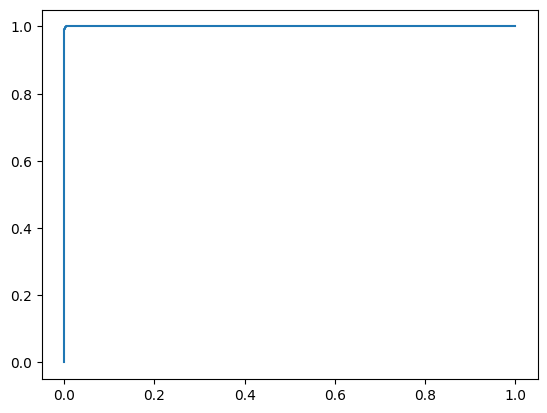

In [ ]:
# Importing GridSearchCV for optimization
from sklearn.model_selection import GridSearchCV

# We assume Logistic Regression (LR) was selected as the best based on AUC-ROC
# Defining the parameter grid for LR
param_grid_lr = {
    'C': [0.01, 0.1, 1, 10, 100],
    'penalty': ['l2'],
    'solver': ['lbfgs', 'liblinear']
}

# Initializing GridSearchCV with 5-fold cross-validation
grid_search = GridSearchCV(LogisticRegression(random_state=42), param_grid_lr, cv=5, scoring='accuracy')

# Fitting the grid search on the training data (using imputed data)
grid_search.fit(X_train_final, y_train)

# Documenting the best hyperparameters
print("Best Hyperparameters for Logistic Regression:", grid_search.best_params_)

# Evaluating the optimized model (using imputed test data)
best_lr = grid_search.best_estimator_
evaluate_model(best_lr, X_test_final, y_test, "Optimized Logistic Regression")